# Lab 1 - Filtering Operations
---

## Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift
from scipy.signal import convolve2d
from Functions import *
from fftwave import fftwave

# 1.3 Basis functions

## Question 1

Point: (5, 9)


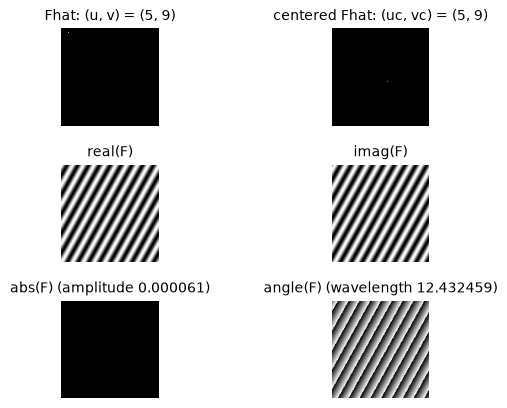

Point: (9, 5)


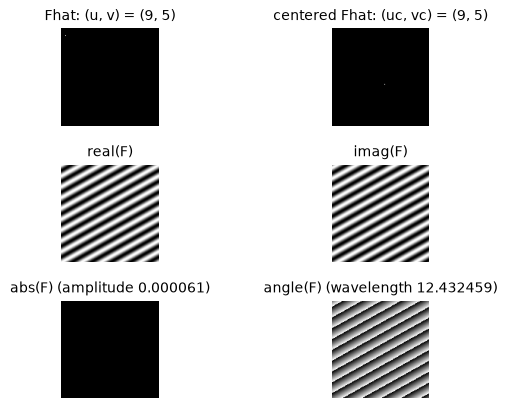

Point: (17, 9)


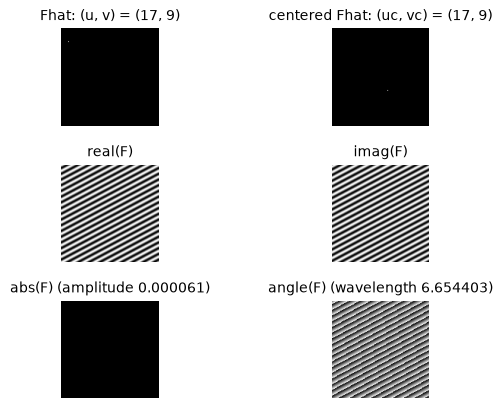

Point: (17, 121)


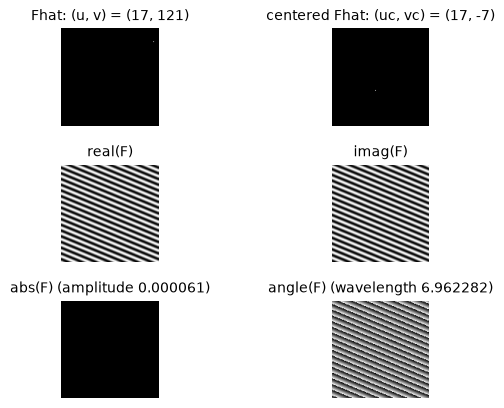

Point: (5, 1)


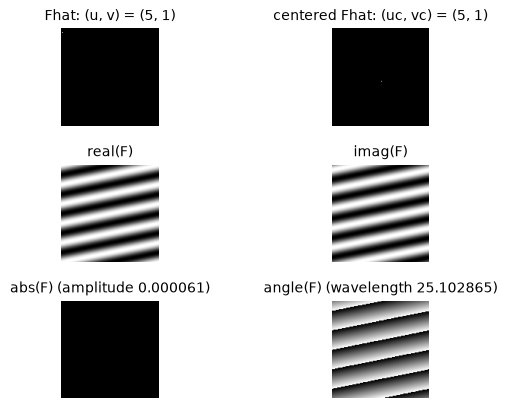

Point: (125, 1)


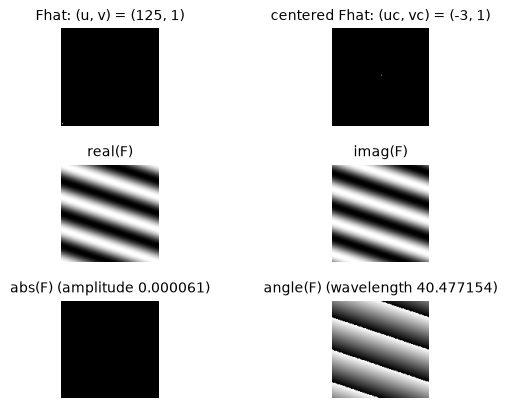

In [3]:
points = [
    (5, 9),
    (9, 5),
    (17, 9),
    (17, 121),
    (5, 1),
    (125, 1)
]

for (p, q) in points:
    print(f"Point: ({p}, {q})")
    wave = fftwave(p, q)

## Question 2

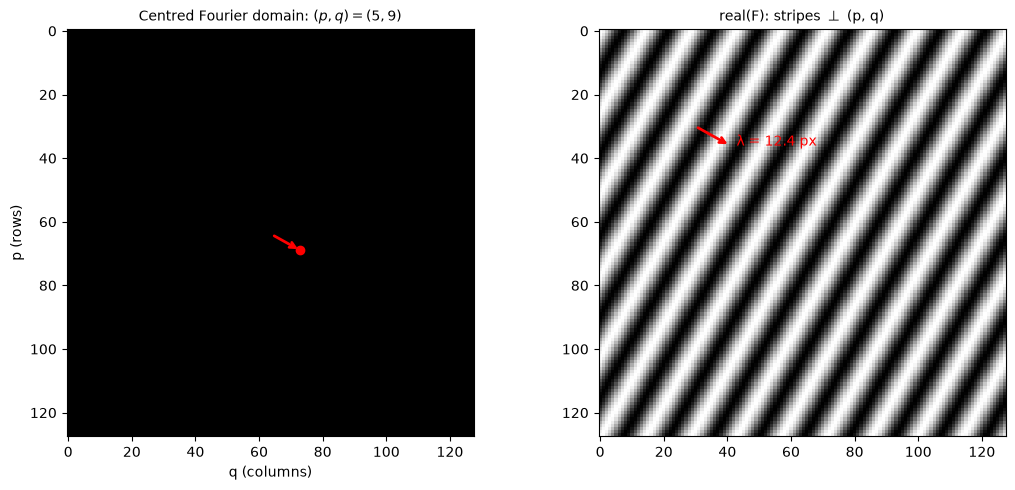

In [4]:
N, p, q = 128, 5, 9
Fhat = np.zeros((N, N)); Fhat[p, q] = 1
F = np.fft.ifft2(Fhat)

pc = p if p < N/2 else p - N
qc = q if q < N/2 else q - N
r = np.hypot(pc, qc)
lam = N / r

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5))

# Left: centred Fourier domain, origin at (N/2, N/2)
a1.imshow(np.fft.fftshift(Fhat), cmap='gray')
c = N // 2
a1.plot(c + qc, c + pc, 'ro', ms=6)
a1.annotate('', xy=(c + qc, c + pc), xytext=(c, c),
            arrowprops=dict(color='red', arrowstyle='->', lw=2))
a1.set_title(rf"Centred Fourier domain: $(p, q) = ({pc}, {qc})$")
a1.set_xlabel("q (columns)"); a1.set_ylabel("p (rows)")

# Right: real part, with an arrow of length one wavelength along (p, q)
a2.imshow(np.real(F), cmap='gray')
x0, y0 = 30, 30
a2.annotate('', xy=(x0 + lam*qc/r, y0 + lam*pc/r), xytext=(x0, y0),
            arrowprops=dict(color='red', arrowstyle='->', lw=2))
a2.text(x0 + lam*qc/r + 2, y0 + lam*pc/r, f"λ = {lam:.1f} px", color='red')
a2.set_title(r"real(F): stripes $\bot$ (p, q)")

plt.tight_layout()
plt.savefig("lab1_q2.png", dpi=300)
plt.show()

## Question 5

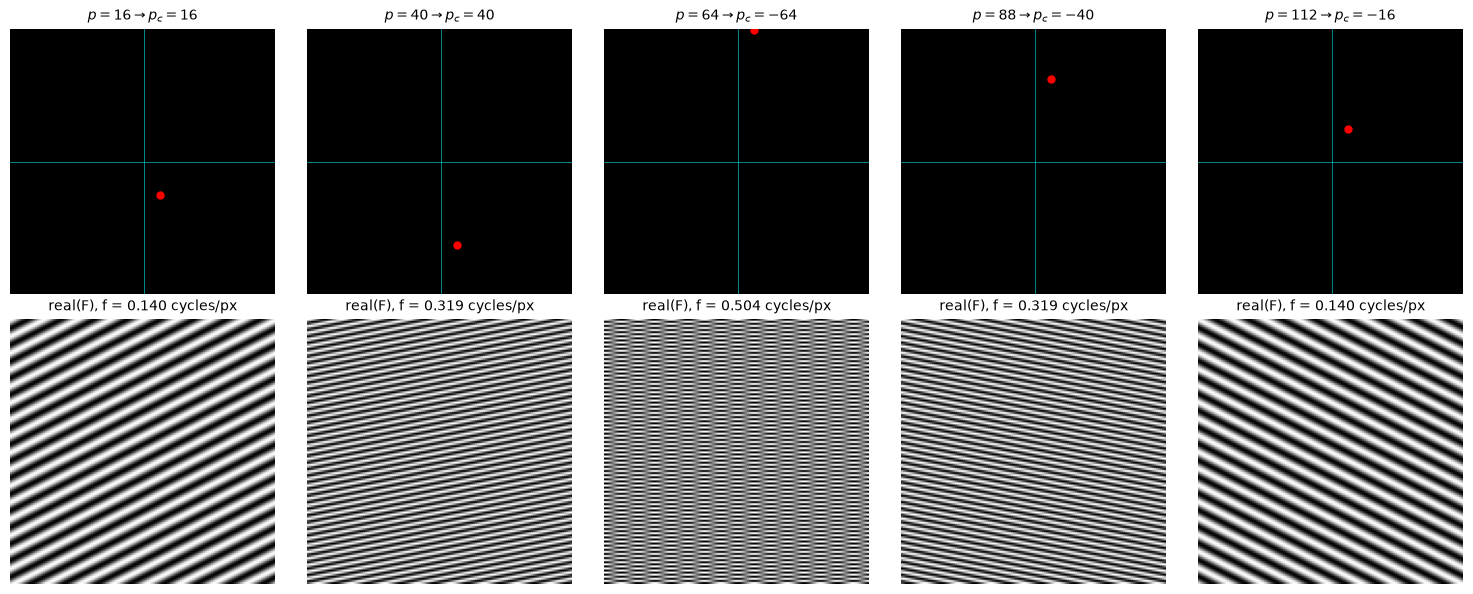

In [5]:
N, q = 128, 8
ps = [16, 40, 64, 88, 112]

fig, axes = plt.subplots(2, len(ps), figsize=(15, 6))
for k, p in enumerate(ps):
    Fhat = np.zeros((N, N)); Fhat[p, q] = 1
    F = np.fft.ifft2(Fhat)
    pc = p if p < N/2 else p - N
    f = np.hypot(pc, q) / N

    # Top: point in the centred Fourier domain, origin at (N/2, N/2)
    a = axes[0, k]
    a.imshow(np.fft.fftshift(Fhat), cmap='gray')
    a.plot(N//2 + q, N//2 + pc, 'ro', ms=5)
    a.axhline(N//2, color='c', lw=0.5); a.axvline(N//2, color='c', lw=0.5)
    a.set_title(rf"$p = {p} \rightarrow p_c = {pc}$")
    a.axis('off')

    # Bottom: resulting wave in the spatial domain
    a = axes[1, k]
    a.imshow(np.real(F), cmap='gray')
    a.set_title(f"real(F), f = {f:.3f} cycles/px")
    a.axis('off')

plt.tight_layout()
plt.savefig("lab1_q5_sweep.png", dpi=300)
plt.show()

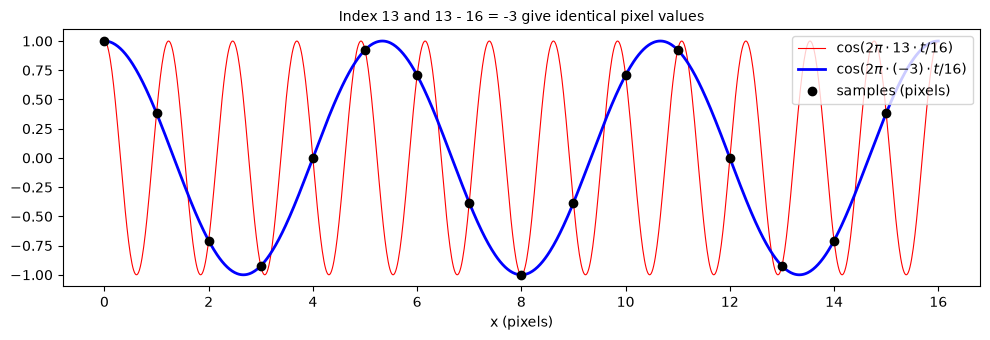

In [6]:
# 1D view: index p and p - N give the same pixel values
n, p = 16, 13
t = np.linspace(0, n, 1000); x = np.arange(n)

plt.figure(figsize=(10, 3.5))
plt.plot(t, np.cos(2*np.pi*p*t/n), 'r', lw=0.8, label=rf"$\cos(2\pi \cdot {p} \cdot t/{n})$")
plt.plot(t, np.cos(2*np.pi*(p-n)*t/n), 'b', lw=2, label=rf"$\cos(2\pi \cdot ({p-n}) \cdot t/{n})$")
plt.plot(x, np.cos(2*np.pi*p*x/n), 'ko', label="samples (pixels)")
plt.legend(loc='upper right'); plt.xlabel("x (pixels)")
plt.title(f"Index {p} and {p} - {n} = {p-n} give identical pixel values")

plt.tight_layout()
plt.savefig("lab1_q5_alias.png", dpi=300)
plt.show()

# 1.4 Linearity

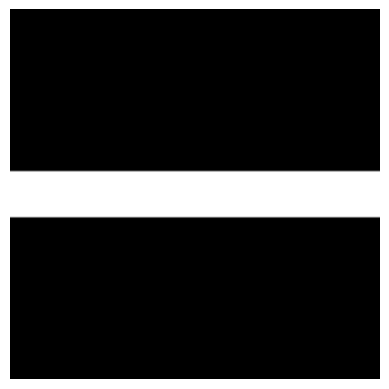

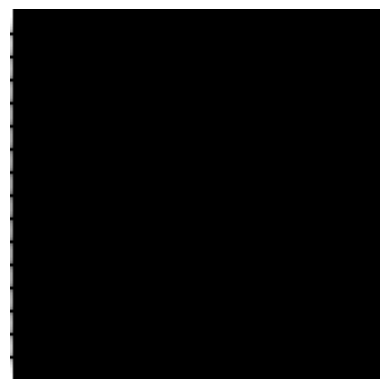

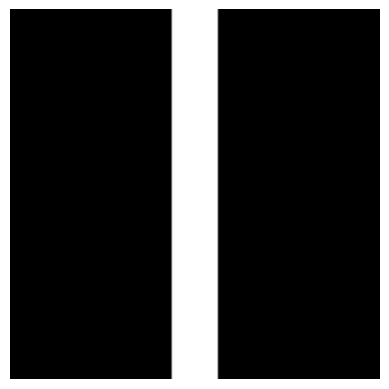

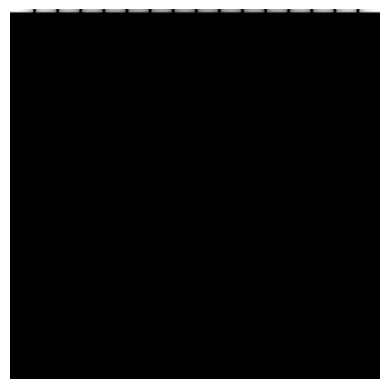

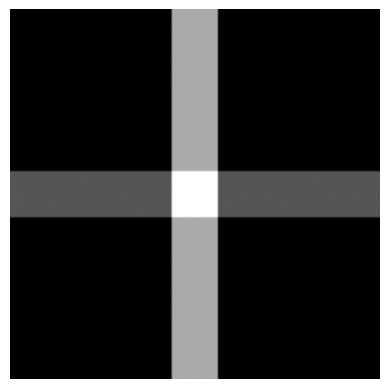

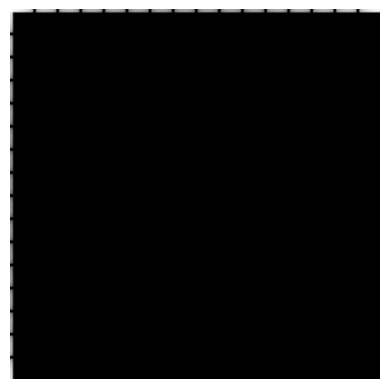

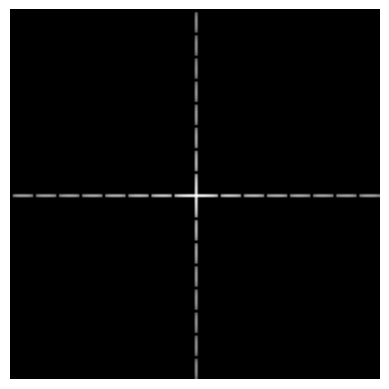

In [9]:
F = np.concatenate([np.zeros((56,128)), np.ones((16,128)), np.zeros((56,128))])
G = F.T
H = F + 2*G

Fhat = fft2(F)
Ghat = fft2(G)
Hhat = fft2(H)

showgrey(F)
showgrey(np.log(1 + np.abs(Fhat)))
showgrey(G)
showgrey(np.log(1 + np.abs(Ghat)))
showgrey(H)
showgrey(np.log(1 + np.abs(Hhat)))

showgrey(np.log(1 + np.abs(fftshift(Hhat))))

# 1.5 Multiplication

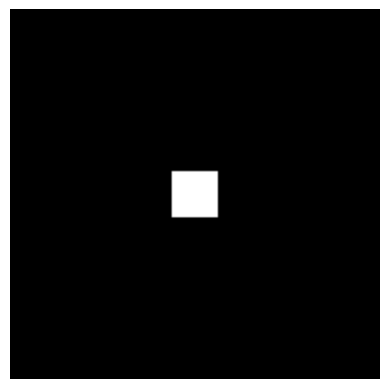

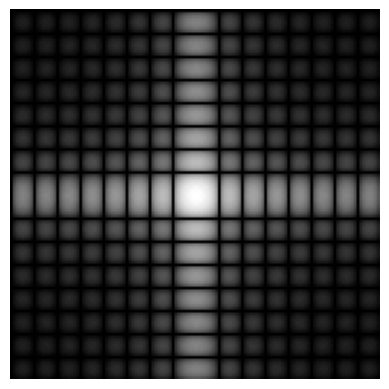

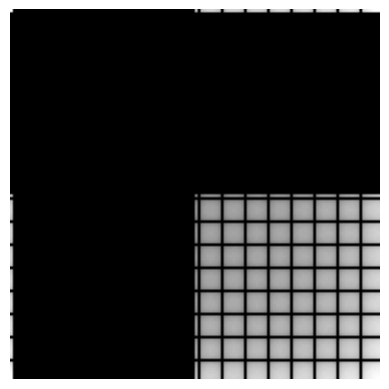

In [ ]:
F = np.concatenate([np.zeros((56,128)), np.ones((16,128)), np.zeros((56,128))])
G = F.T

showgrey(F * G)
showfs(fft2(F * G))

# F_hat = fft2(F)
# G_hat = fft2(G)
# # Convolution of F_hat and G_hat
# H = convolve2d(F_hat, G_hat, mode='same')
# showfs(H)

## Question 10

max |direct - conv| = 5.684341886080802e-14
max |direct - sep|  = 4.119604422216382e-14


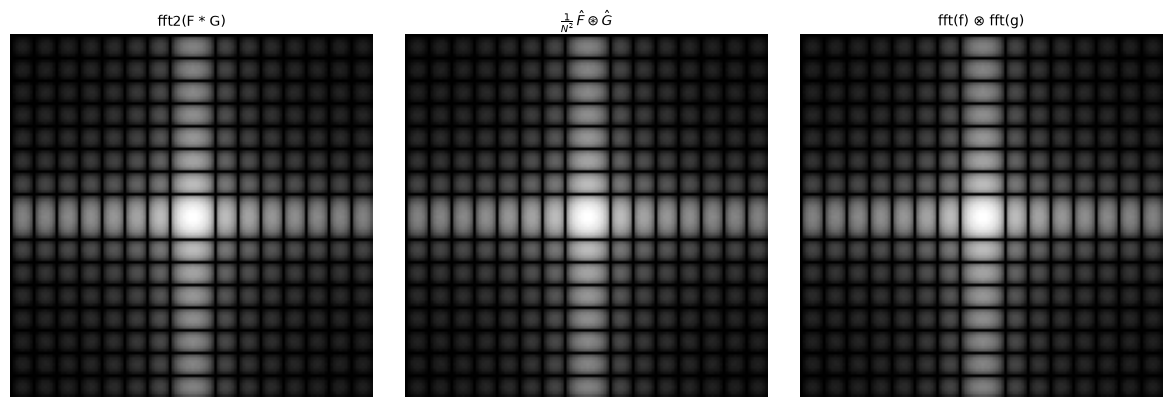

In [15]:
N = F.shape[0]
Fhat = fft2(F)
Ghat = fft2(G)

# 1) Direct: transform of the pointwise product
direct = fft2(F * G)

# 2) Convolution theorem: circular convolution of the spectra, scaled by 1/N^2
#    convolve2d computes a linear convolution of size (2N-1, 2N-1);
#    folding the overflow back onto [0, N-1]^2 makes it circular (periodic)
full = convolve2d(Fhat, Ghat)
circ = full[:N, :N].copy()
circ[:N-1, :] += full[N:, :N]
circ[:, :N-1] += full[:N, N:]
circ[:N-1, :N-1] += full[N:, N:]
conv = circ / N**2

# 3) Separability: F * G = f g^T, so its 2D DFT is the outer product of two 1D DFTs
f = F[:, 0]   # vertical profile of F (each row is constant)
g = G[0, :]   # horizontal profile of G (each column is constant)
sep = np.outer(np.fft.fft(f), np.fft.fft(g))

print("max |direct - conv| =", np.max(np.abs(direct - conv)))
print("max |direct - sep|  =", np.max(np.abs(direct - sep)))

plt.figure(figsize=(12, 4))
for k, (im, title) in enumerate([(direct, "fft2(F * G)"),
                                 (conv, r"$\frac{1}{N^2}\,\hat F \circledast \hat G$"),
                                 (sep, r"fft(f) $\otimes$ fft(g)")]):
    plt.subplot(1, 3, k + 1)
    showfs(im, False)
    plt.title(title)
plt.tight_layout()
plt.savefig("lab1_q10.png", dpi=300)
plt.show()

# 1.6 Scaling

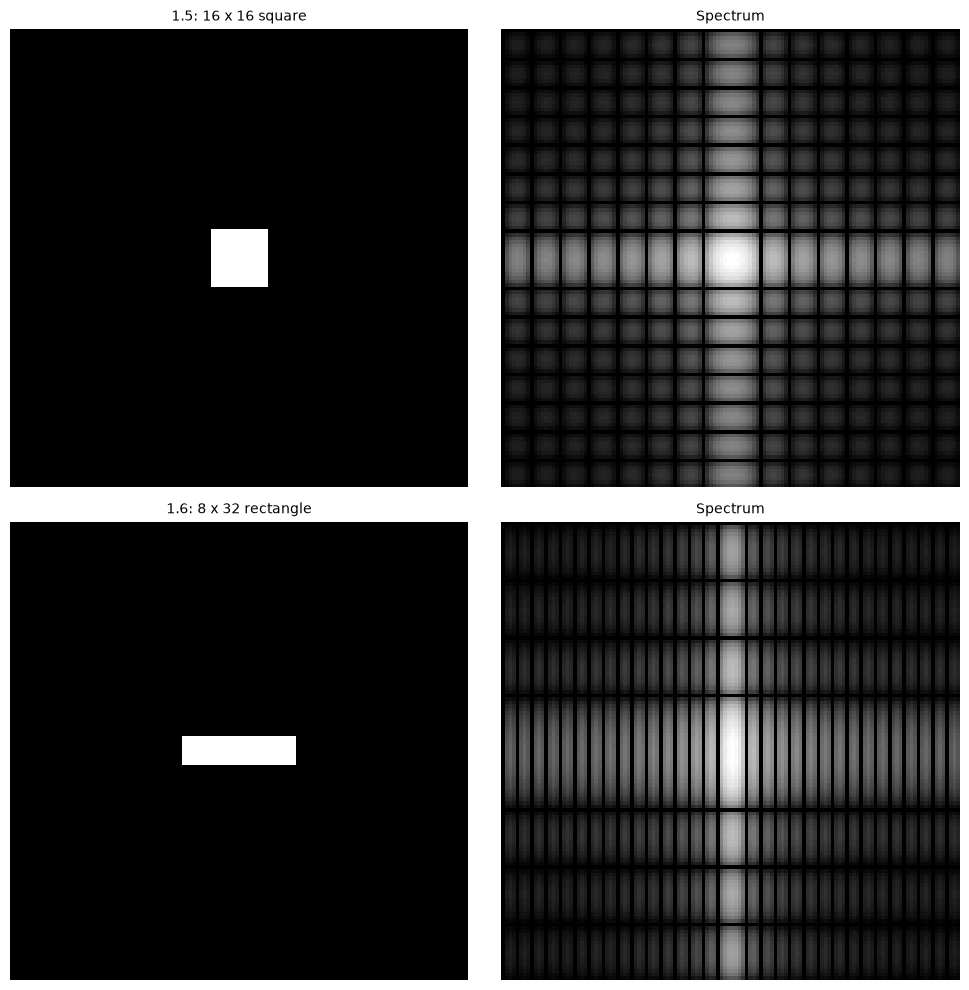

In [16]:
F = np.concatenate([np.zeros((60,128)), np.ones((8,128)), np.zeros((60,128))]) * \
    np.concatenate([np.zeros((128,48)), np.ones((128,32)), np.zeros((128,48))], axis=1)
Fhat = fft2(F)

# Compare with the 16 x 16 square from 1.5
square = np.concatenate([np.zeros((56,128)), np.ones((16,128)), np.zeros((56,128))])
square = square * square.T

plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1); showgrey(square, False); plt.title("1.5: 16 x 16 square")
plt.subplot(2, 2, 2); showfs(fft2(square), False); plt.title("Spectrum")
plt.subplot(2, 2, 3); showgrey(F, False); plt.title("1.6: 8 x 32 rectangle")
plt.subplot(2, 2, 4); showfs(Fhat, False); plt.title("Spectrum")
plt.tight_layout()
plt.savefig("lab1_q11.png", dpi=300)
plt.show()

# 1.7 Rotation

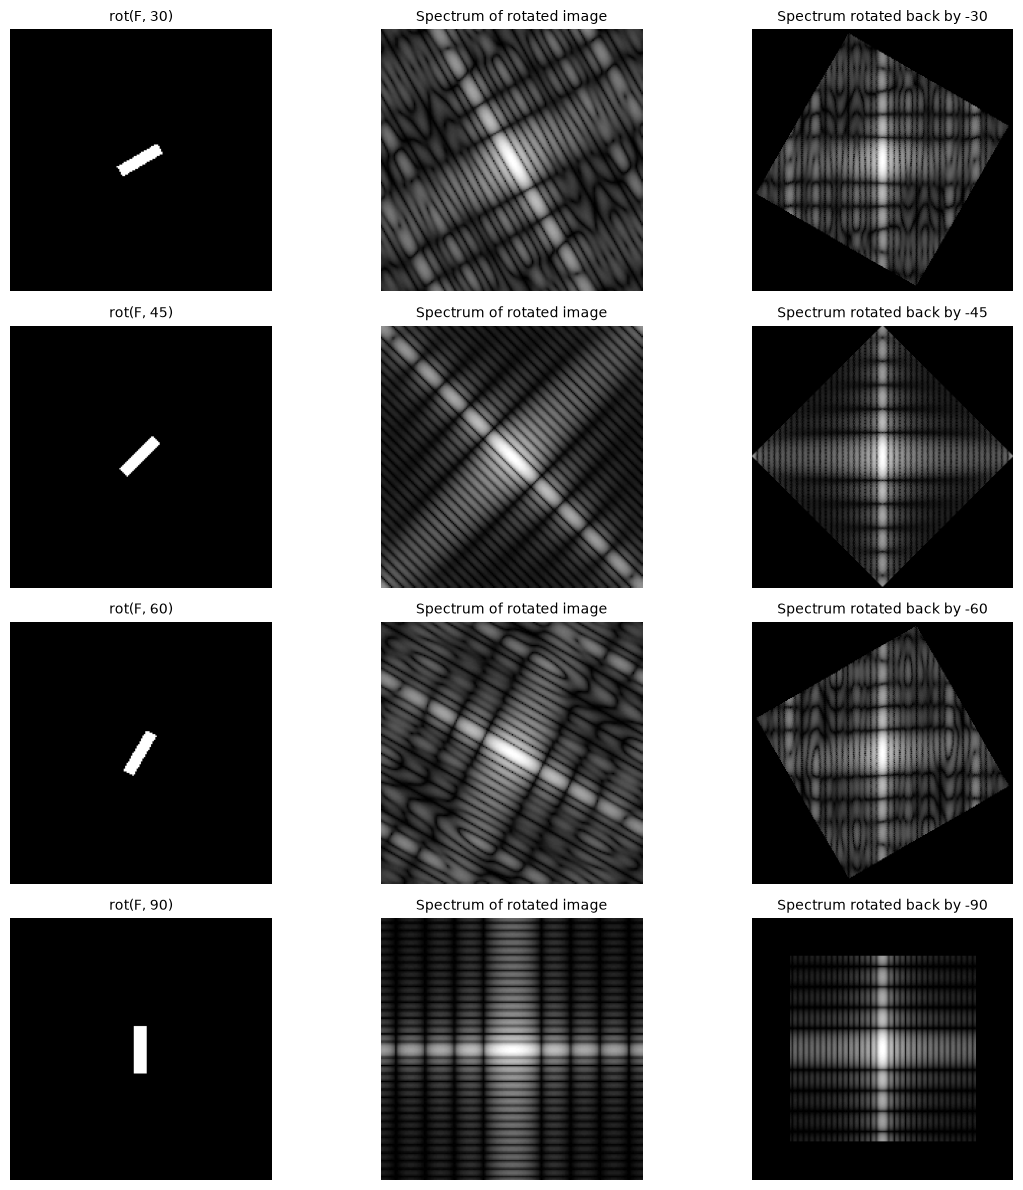

In [17]:
angles = [30, 45, 60, 90]

plt.figure(figsize=(12, 3 * len(angles)))
for k, alpha in enumerate(angles):
    G = rot(F, alpha)
    Ghat = fft2(G)
    Hhat = rot(fftshift(Ghat), -alpha)

    plt.subplot(len(angles), 3, 3*k + 1); showgrey(G, False); plt.title(f"rot(F, {alpha})")
    plt.subplot(len(angles), 3, 3*k + 2); showfs(Ghat, False); plt.title("Spectrum of rotated image")
    plt.subplot(len(angles), 3, 3*k + 3); showgrey(np.log(1 + np.abs(Hhat)), False); plt.title(f"Spectrum rotated back by -{alpha}")
plt.tight_layout()
plt.savefig("lab1_q12.png", dpi=300)
plt.show()

# 1.8 Information in Fourier phase and magnitude

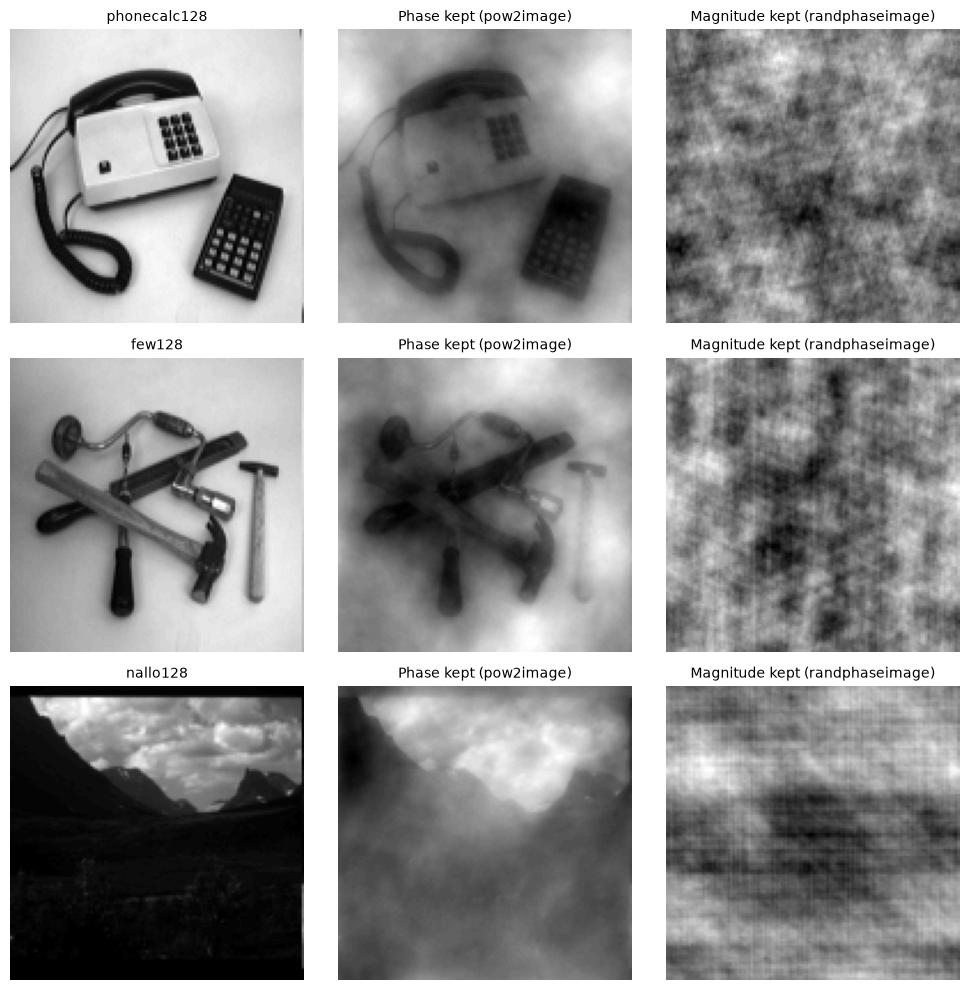

In [18]:
names = ["phonecalc128", "few128", "nallo128"]
a = 1e-3

plt.figure(figsize=(10, 10))
for k, name in enumerate(names):
    img = np.load(f"Images-npy/{name}.npy")
    plt.subplot(3, 3, 3*k + 1); showgrey(img, False); plt.title(name)
    plt.subplot(3, 3, 3*k + 2); showgrey(pow2image(img, a), False); plt.title("Phase kept (pow2image)")
    plt.subplot(3, 3, 3*k + 3); showgrey(randphaseimage(img), False); plt.title("Magnitude kept (randphaseimage)")
plt.tight_layout()
plt.savefig("lab1_q13.png", dpi=300)
plt.show()

# 2.3 Gaussian filtering via FFT

t = 0.1:
[[1.32967252e-02 1.24900090e-15]
 [1.24900090e-15 1.32967252e-02]]

t = 0.3:
[[ 2.81053830e-01 -4.24660307e-15]
 [-4.24660307e-15  2.81053830e-01]]

t = 1.0:
[[9.99999789e-01 3.83026943e-15]
 [3.83026943e-15 9.99999789e-01]]

t = 10.0:
[[ 1.00000000e+01 -1.57096558e-14]
 [-1.57096558e-14  1.00000000e+01]]

t = 100.0:
[[ 9.99999993e+01 -5.55111512e-15]
 [-5.55111512e-15  9.99999993e+01]]



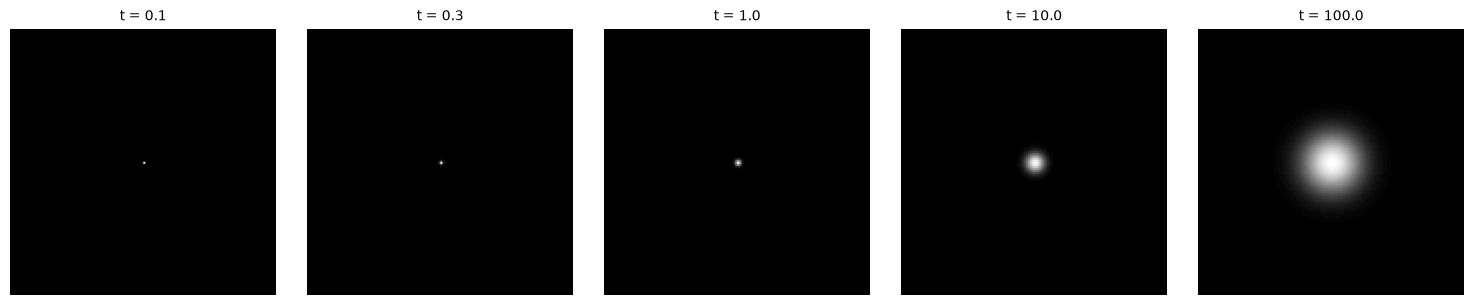

In [19]:
from gaussfft import gaussfft

ts = [0.1, 0.3, 1.0, 10.0, 100.0]

plt.figure(figsize=(15, 3))
for k, t in enumerate(ts):
    psf = gaussfft(deltafcn(128, 128), t)
    print(f"t = {t}:\n{variance(psf)}\n")
    plt.subplot(1, len(ts), k + 1); showgrey(psf, False); plt.title(f"t = {t}")
plt.tight_layout()
plt.savefig("lab1_q14.png", dpi=300)
plt.show()

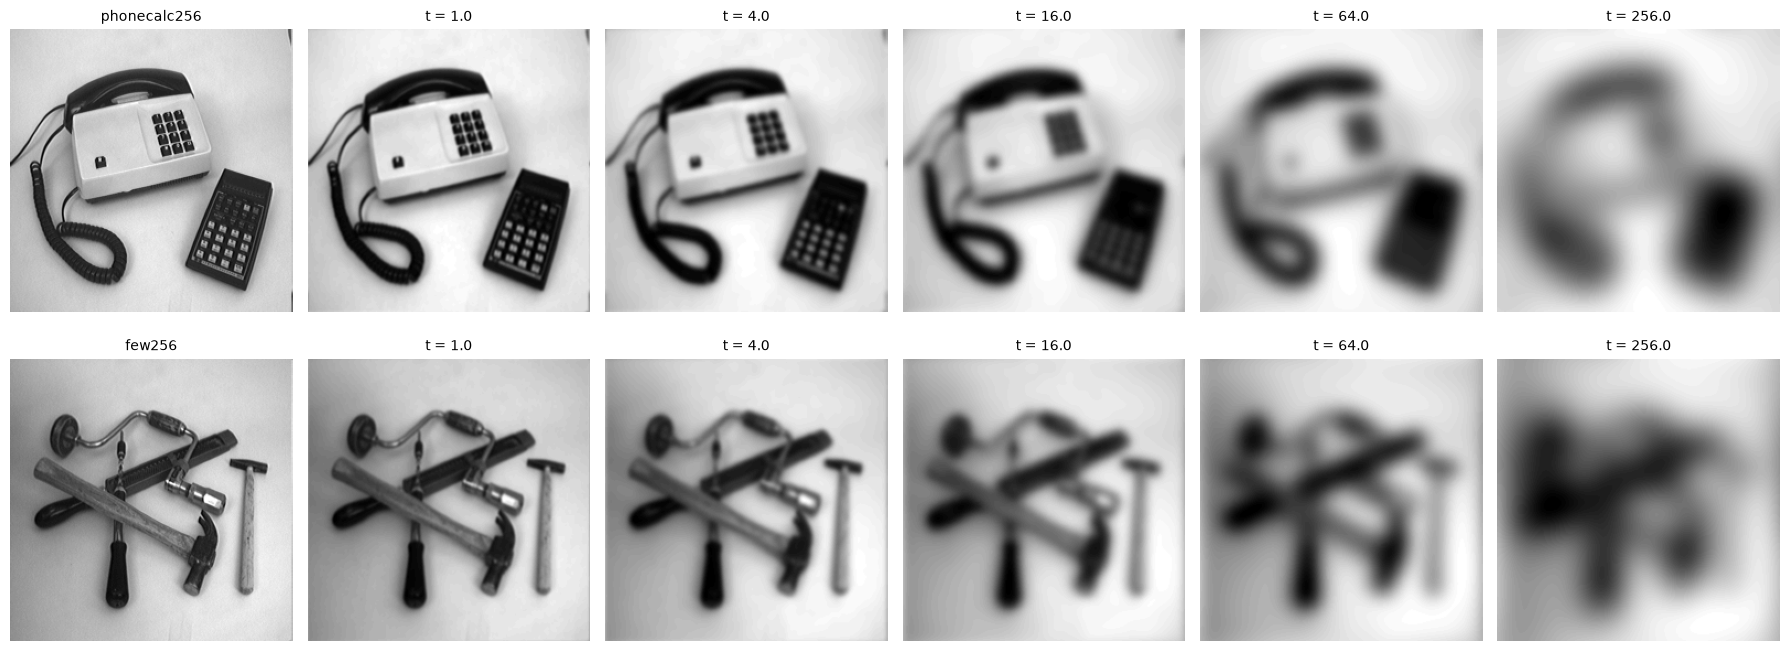

In [20]:
ts = [1.0, 4.0, 16.0, 64.0, 256.0]
names = ["phonecalc256", "few256"]

plt.figure(figsize=(18, 7))
for i, name in enumerate(names):
    img = np.load(f"Images-npy/{name}.npy")
    plt.subplot(len(names), len(ts) + 1, i*(len(ts) + 1) + 1); showgrey(img, False); plt.title(name)
    for k, t in enumerate(ts):
        plt.subplot(len(names), len(ts) + 1, i*(len(ts) + 1) + k + 2)
        showgrey(gaussfft(img, t), False); plt.title(f"t = {t}")
plt.tight_layout()
plt.savefig("lab1_q16.png", dpi=300)
plt.show()

# 3.1 Smoothing of noisy data

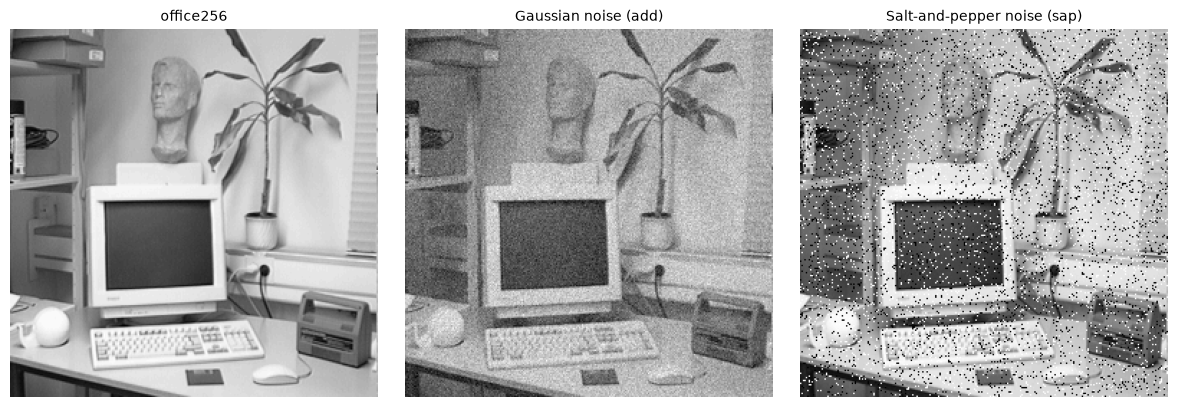

In [21]:
office = np.load("Images-npy/office256.npy")
add = gaussnoise(office, 16)
sap = sapnoise(office.copy(), 0.1, 255)   # copy: sapnoise modifies its input

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); showgrey(office, False); plt.title("office256")
plt.subplot(1, 3, 2); showgrey(add, False); plt.title("Gaussian noise (add)")
plt.subplot(1, 3, 3); showgrey(sap, False); plt.title("Salt-and-pepper noise (sap)")
plt.tight_layout()
plt.show()

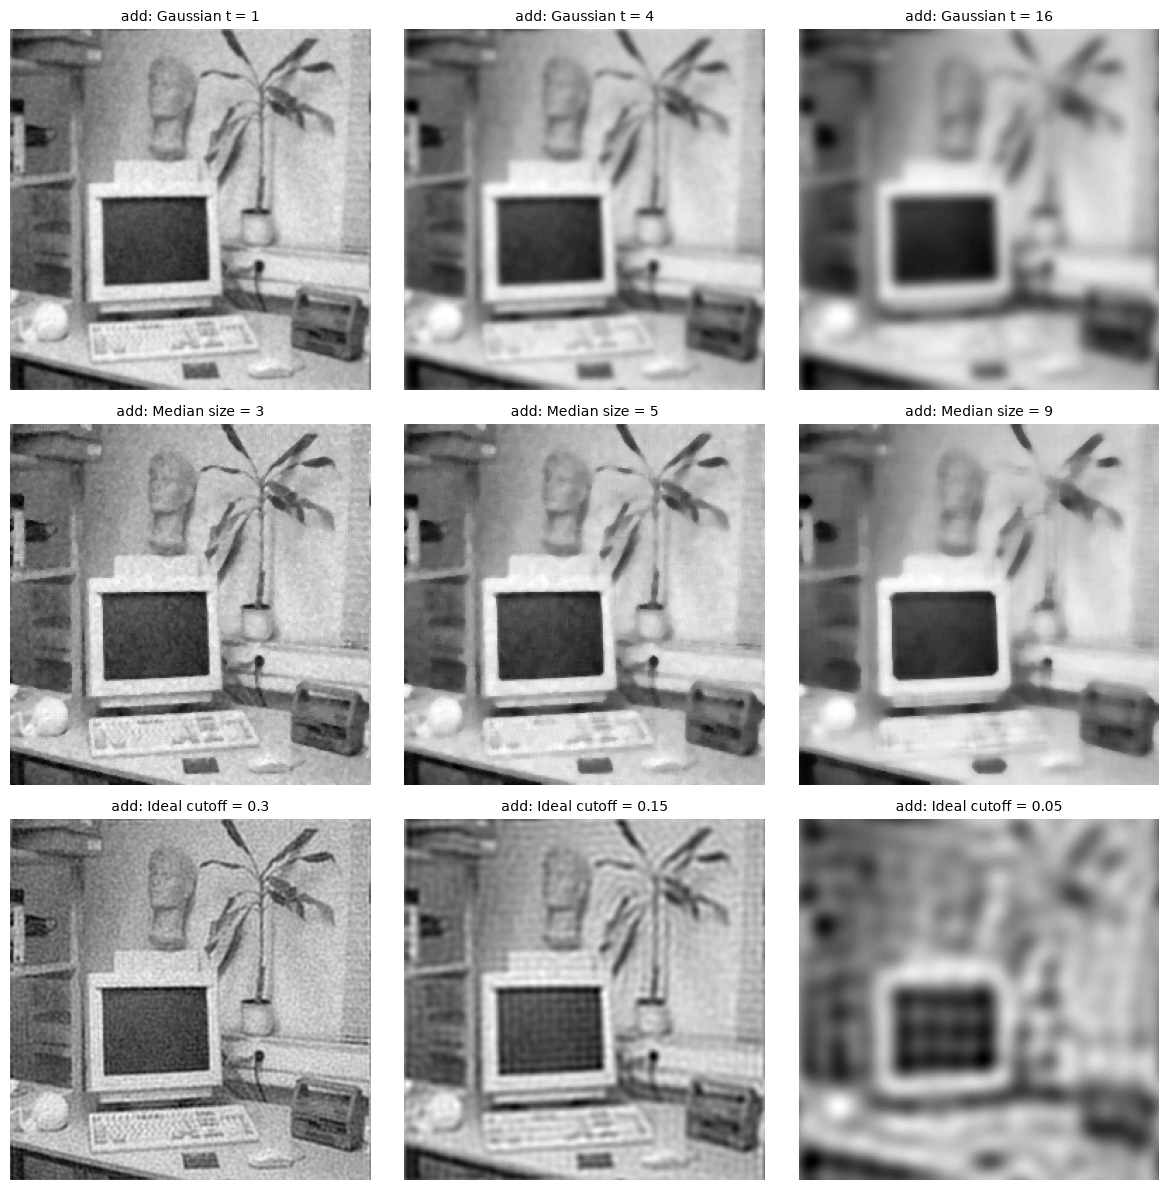

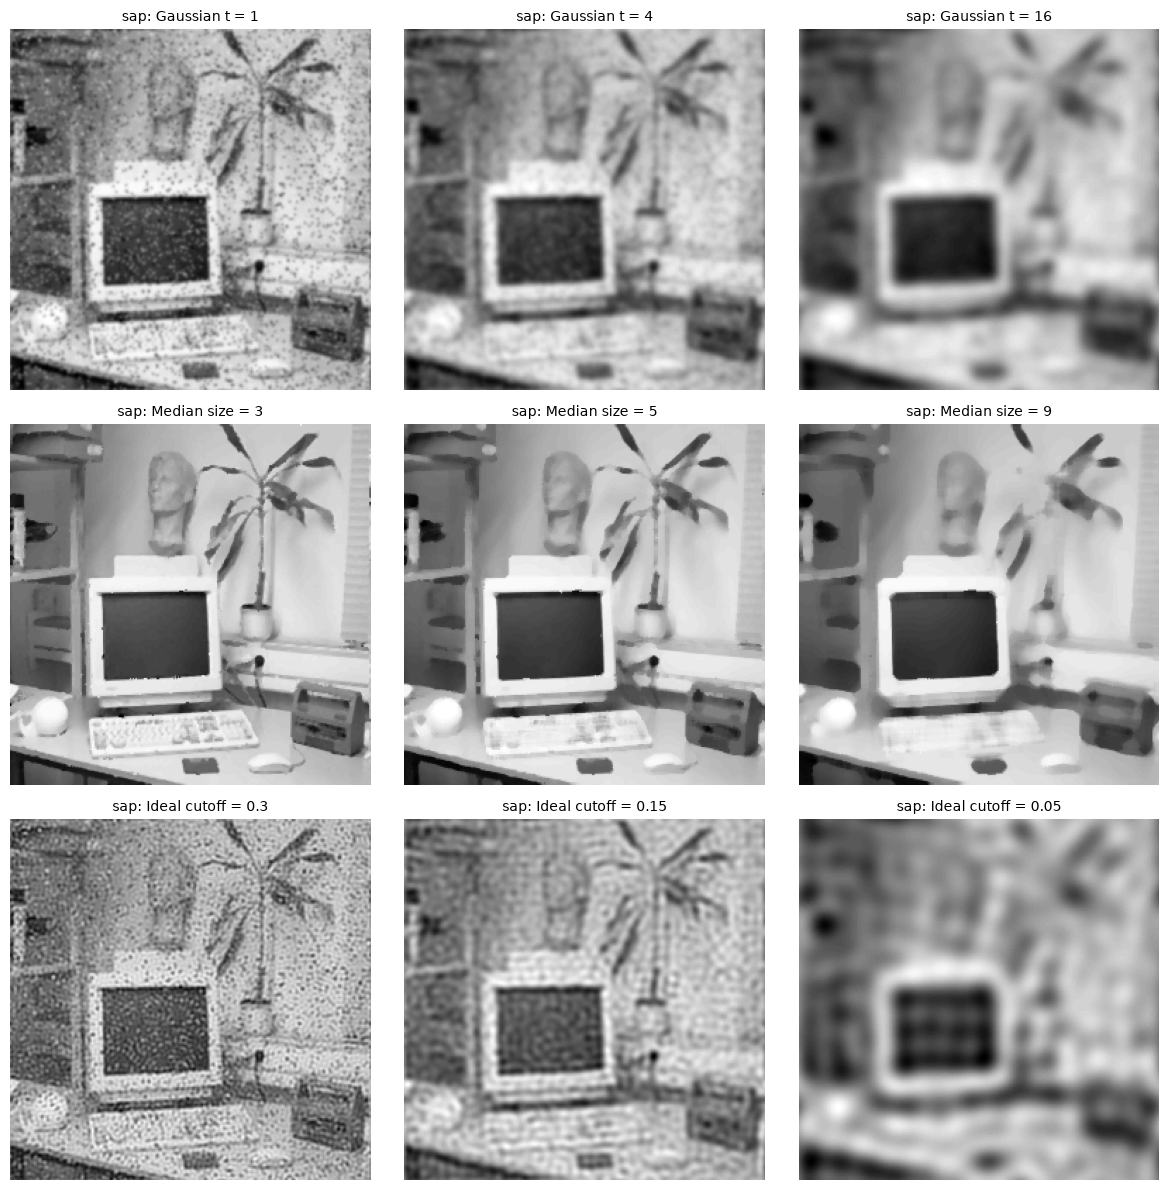

In [22]:
# Each filter with a weak, a medium and a strong parameter, applied to both noisy images
filters = [
    ("Gaussian t", lambda im, p: gaussfft(im, p), [1, 4, 16]),
    ("Median size", lambda im, p: medfilt(im, p), [3, 5, 9]),
    ("Ideal cutoff", lambda im, p: ideal(im, p), [0.3, 0.15, 0.05]),
]

for noisy, label in [(add, "add"), (sap, "sap")]:
    plt.figure(figsize=(12, 12))
    for i, (name, filt, params) in enumerate(filters):
        for k, p in enumerate(params):
            plt.subplot(3, 3, 3*i + k + 1)
            showgrey(filt(noisy, p), False)
            plt.title(f"{label}: {name} = {p}")
    plt.tight_layout()
    plt.savefig(f"lab1_q17_{label}.png", dpi=300)
    plt.show()

# 3.2 Smoothing and subsampling

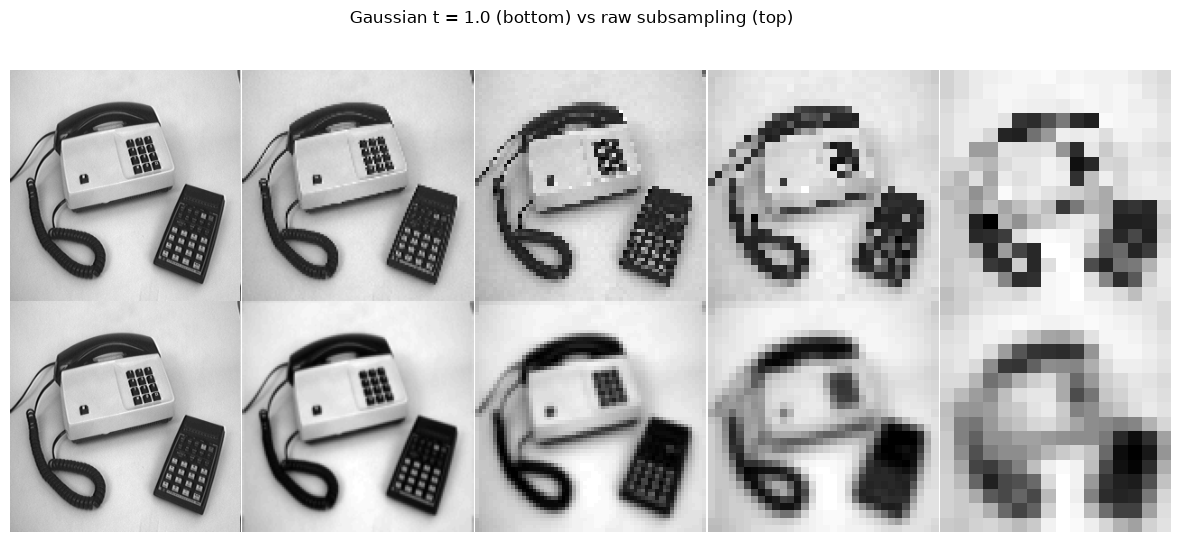

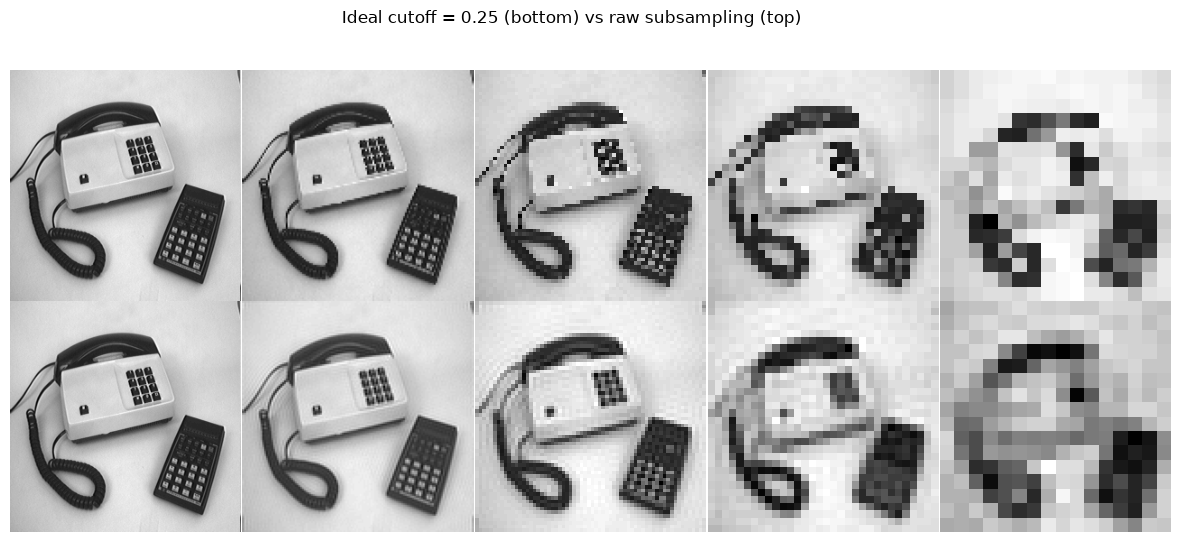

In [23]:
def subsample_series(filt, title):
    img = np.load("Images-npy/phonecalc256.npy")
    smoothimg = img
    N = 5
    f = plt.figure(figsize=(15, 6))
    f.subplots_adjust(wspace=0, hspace=0)
    for i in range(N):
        if i > 0:  # generate subsampled versions
            img = rawsubsample(img)
            smoothimg = filt(smoothimg)
            smoothimg = rawsubsample(smoothimg)
        f.add_subplot(2, N, i + 1)
        showgrey(img, False)
        f.add_subplot(2, N, i + N + 1)
        showgrey(smoothimg, False)
    f.suptitle(title)
    plt.savefig(f"lab1_q19_{title.split()[0].lower()}.png", dpi=300)
    plt.show()

subsample_series(lambda im: gaussfft(im, 1.0), "Gaussian t = 1.0 (bottom) vs raw subsampling (top)")
subsample_series(lambda im: ideal(im, 0.25), "Ideal cutoff = 0.25 (bottom) vs raw subsampling (top)")